In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/Medical-Vision-AI-XAI'

for d in ['data', 'notebooks', 'src', 'models', 'results', 'app']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)

for f in ['src/preprocessing.py', 'src/train.py', 'src/evaluate.py',
          'src/gradcam.py', 'app/streamlit_app.py',
          'requirements.txt', 'README.md']:
    open(f'{PROJECT}/{f}', 'a').close()

print(os.listdir(PROJECT))

Mounted at /content/drive
['data', 'notebooks', 'src', 'models', 'results', 'app', 'requirements.txt', 'README.md']


Download the dataset from **Kaggle**

In [ ]:
KGAT_3212c286107f1f7f760fe067a31ef787

In [ ]:
import os
from getpass import getpass

!pip install -q --upgrade kaggle imagehash
os.environ['KAGGLE_API_TOKEN'] = getpass('Paste Kaggle token: ')

!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/data --unzip
!ls /content/data

Paste Kaggle token: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:02<00:00, 75.3MB/s]

Testing  Training


**build the manifest**

In [ ]:
from pathlib import Path
import pandas as pd

DATA = Path('/content/data')
rows = []
for split in ['Training', 'Testing']:
    for p in (DATA / split).rglob('*'):
        if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
            rows.append({'path': str(p), 'split': split, 'label': p.parent.name})

df = pd.DataFrame(rows)
print(df.shape)
print(df.groupby(['split', 'label']).size().unstack())

(7200, 3)
label     glioma  meningioma  notumor  pituitary
split                                           
Testing      400         400      400        400
Training    1400        1400     1400       1400


**class distribution plot**

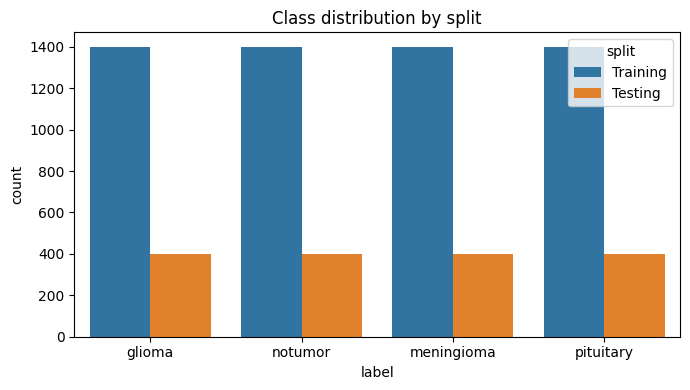

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x='label', hue='split', ax=ax)
ax.set_title('Class distribution by split')
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/class_distribution.png', dpi=200)
plt.show()

**look at the images and check their properties**

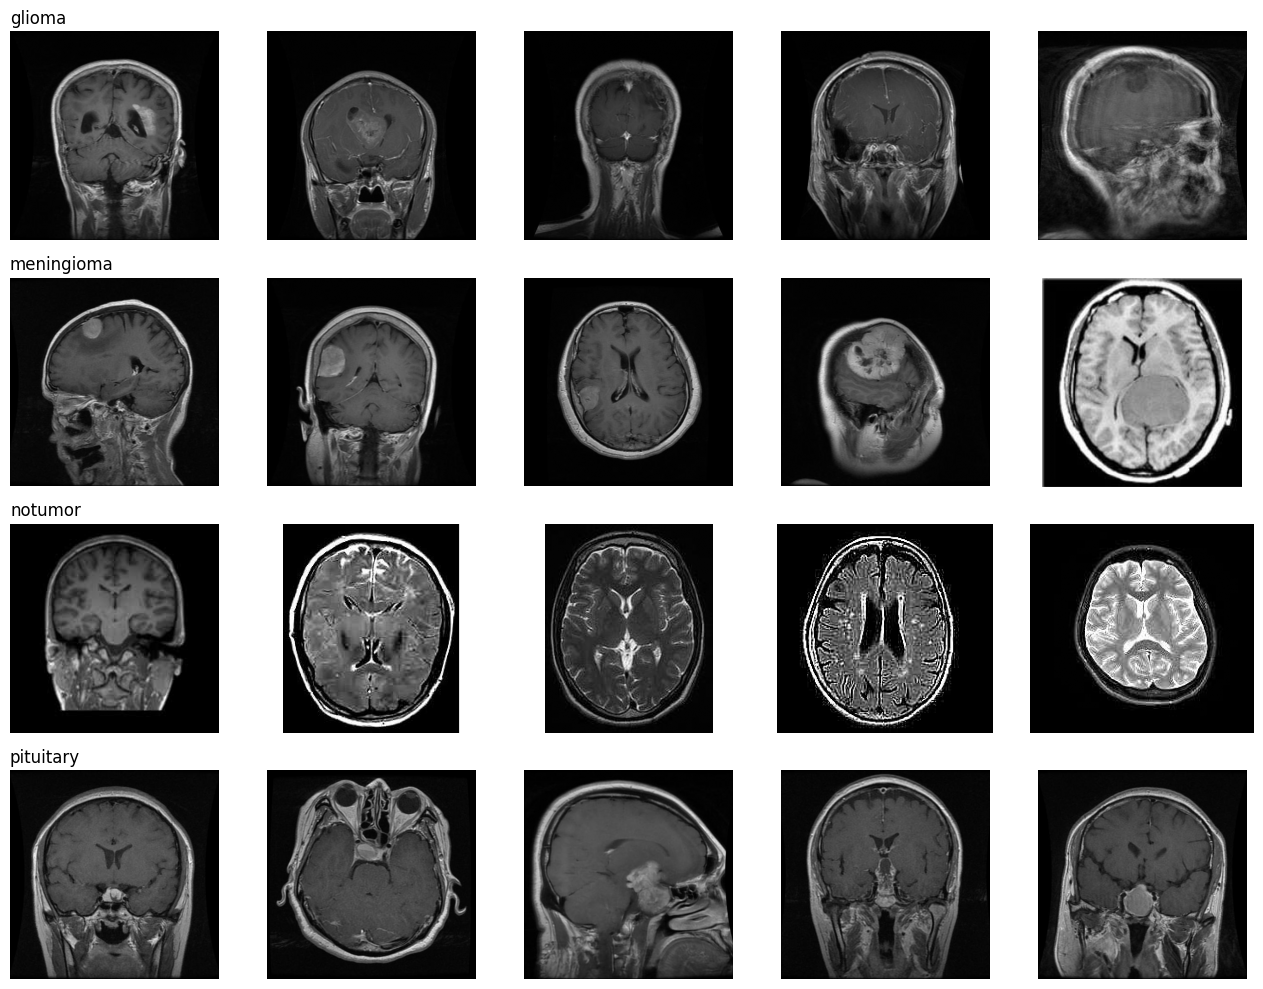

            width       height
min    150.000000   167.000000
max   1375.000000  1446.000000
mean   453.302917   456.899167
mode
RGB     4129
L       3067
RGBA       3
P          1
Name: count, dtype: int64


In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(13, 10))
for i, c in enumerate(classes):
    sample = df[(df.label == c) & (df.split == 'Training')].sample(5, random_state=42)
    for j, p in enumerate(sample.path):
        axes[i, j].imshow(Image.open(p).convert('L'), cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(c, loc='left', fontsize=12)
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/sample_images.png', dpi=200)
plt.show()

# image size and color mode statistics
sizes, modes = [], []
for p in df.path:
    with Image.open(p) as im:
        sizes.append(im.size)
        modes.append(im.mode)
df['width'] = [s[0] for s in sizes]
df['height'] = [s[1] for s in sizes]
df['mode'] = modes

print(df[['width', 'height']].describe().loc[['min', 'max', 'mean']])
print(df['mode'].value_counts())

**Step 5b: Quick shortcut check**

In [ ]:
print(df.groupby('label')[['width', 'height']].mean().round(0))
print()
print(pd.crosstab(df['label'], df['mode']))

            width  height
label                    
glioma      507.0   508.0
meningioma  487.0   489.0
notumor     308.0   319.0
pituitary   512.0   511.0

mode           L  P   RGB  RGBA
label                          
glioma      1399  0   401     0
meningioma   709  0  1091     0
notumor       29  1  1767     3
pituitary    930  0   870     0


**Step 6: Duplicate and near-duplicate check**

In [ ]:
import numpy as np
import imagehash
from tqdm import tqdm

hashes = []
for p in tqdm(df.path):
    with Image.open(p) as im:
        hashes.append(imagehash.phash(im.convert('L')).hash.flatten())

H = np.array(hashes).astype(np.float32)           # N x 64 of 0/1
D = H @ (1 - H).T + (1 - H) @ H.T                 # N x N Hamming distances

split = df['split'].values
label = df['label'].values

def find_pairs(thr):
    i, j = np.where(np.triu(D <= thr, k=1))       # each pair once
    return pd.DataFrame({'i': i, 'j': j, 'dist': D[i, j],
                         'split_i': split[i], 'split_j': split[j],
                         'label_i': label[i], 'label_j': label[j]})

for thr in [0, 4]:
    pairs = find_pairs(thr)
    cross = pairs[pairs.split_i != pairs.split_j]
    within_train = pairs[(pairs.split_i == 'Training') & (pairs.split_j == 'Training')]
    conflict = pairs[pairs.label_i != pairs.label_j]
    print(f'--- Hamming distance <= {thr} ---')
    print(f'total pairs:                 {len(pairs)}')
    print(f'train <-> test (LEAKAGE):    {len(cross)}')
    print(f'within train:                {len(within_train)}')
    print(f'pairs with DIFFERENT labels: {len(conflict)}')

100%|██████████| 7200/7200 [00:29<00:00, 244.00it/s]


--- Hamming distance <= 0 ---
total pairs:                 1930
train <-> test (LEAKAGE):    698
within train:                1070
pairs with DIFFERENT labels: 2
--- Hamming distance <= 4 ---
total pairs:                 5893
train <-> test (LEAKAGE):    2027
within train:                3450
pairs with DIFFERENT labels: 47


**Step 6b: Measure it properly**

In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def groups_at(thr):
    p = find_pairs(thr)
    n = len(df)
    A = coo_matrix((np.ones(len(p)), (p.i.values, p.j.values)), shape=(n, n))
    _, comp = connected_components(A, directed=False)
    return comp

for thr in [0, 4]:
    comp = groups_at(thr)
    g = pd.DataFrame({'comp': comp, 'split': split, 'label': label})
    sizes = g.groupby('comp').size()
    has_both = g.groupby('comp').split.nunique() == 2
    leaky = g[g.comp.isin(has_both[has_both].index)]
    n_label_conflict = (g.groupby('comp').label.nunique() > 1).sum()
    print(f'--- thr {thr} ---')
    print('largest group size:            ', sizes.max())
    print('groups with >1 image:          ', (sizes > 1).sum())
    print('groups spanning train AND test:', has_both.sum())
    print('unique TEST images affected:   ', (leaky.split == 'Testing').sum(), 'of', (g.split == 'Testing').sum())
    print('unique TRAIN images affected:  ', (leaky.split == 'Training').sum(), 'of', (g.split == 'Training').sum())
    print('groups with conflicting labels:', n_label_conflict)

--- thr 0 ---
largest group size:             18
groups with >1 image:           592
groups spanning train AND test: 294
unique TEST images affected:    370 of 1600
unique TRAIN images affected:   485 of 5600
groups with conflicting labels: 1
--- thr 4 ---
largest group size:             28
groups with >1 image:           1103
groups spanning train AND test: 520
unique TEST images affected:    724 of 1600
unique TRAIN images affected:   1306 of 5600
groups with conflicting labels: 25


**Step 7: Clean manifest (threshold as a parameter)**

In [ ]:
def build_keep(thr):
    g = df.copy()
    g['comp'] = groups_at(thr)
    is_train = g.split == 'Training'

    test_comps = set(g.loc[~is_train, 'comp'])
    conflict_comps = set(g.groupby('comp').label.nunique()
                         .loc[lambda s: s > 1].index)

    g['leaks_to_test'] = is_train & g.comp.isin(test_comps)
    g['label_conflict'] = g.comp.isin(conflict_comps)

    ok = is_train & ~g.leaks_to_test & ~g.label_conflict
    g['dup_within_train'] = ok & g.duplicated(subset='comp', keep='first')

    g['keep'] = ~is_train | (ok & ~g.dup_within_train)   # test always kept
    g['test_clean'] = (~is_train) & ~g.comp.isin(set(g.loc[is_train, 'comp']))
    return g

for thr in [0, 4]:
    g = build_keep(thr)
    print(f'--- thr {thr} ---')
    print('train kept:', ((g.split == 'Training') & g.keep).sum(), 'of 5600')
    print('train removed -> leak:', g.leaks_to_test.sum(),
          '| conflict:', (g.label_conflict & (g.split == 'Training')).sum(),
          '| within-train dup:', g.dup_within_train.sum())
    print('clean test images (no copy in original train):', g.test_clean.sum(), 'of 1600')
    print(g[(g.split == 'Training') & g.keep].label.value_counts().to_dict())

THR = 0
final = build_keep(THR)
final.to_csv(f'{PROJECT}/data/manifest.csv', index=False)

--- thr 0 ---
train kept: 4738 of 5600
train removed -> leak: 485 | conflict: 1 | within-train dup: 377
clean test images (no copy in original train): 1230 of 1600
{'glioma': 1393, 'pituitary': 1348, 'meningioma': 1277, 'notumor': 720}
--- thr 4 ---
train kept: 3430 of 5600
train removed -> leak: 1306 | conflict: 96 | within-train dup: 835
clean test images (no copy in original train): 876 of 1600
{'glioma': 1090, 'meningioma': 1017, 'pituitary': 971, 'notumor': 352}


**Check 1: where is the test set contaminated?**

In [ ]:
t = final[final.split == 'Testing']
print(pd.crosstab(t.label, t.test_clean, rownames=['class'], colnames=['clean test image']))
print('\nTest images that are duplicates of another test image:',
      t.duplicated(subset='comp', keep='first').sum())

clean test image  False  True 
class                         
glioma                6    394
meningioma          105    295
notumor             257    143
pituitary             2    398

Test images that are duplicates of another test image: 126


**Check 2: metadata-only baseline (Step 5c) on the cleaned data**

In [ ]:
import os
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

final['filesize_kb'] = [os.path.getsize(p) / 1024 for p in final.path]
final['aspect'] = final.width / final.height
final['is_rgb'] = (final['mode'] != 'L').astype(int)
feats = ['width', 'height', 'aspect', 'filesize_kb', 'is_rgb']

tr = final[(final.split == 'Training') & final.keep]
te = final[final.split == 'Testing']

clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                             class_weight='balanced')
clf.fit(tr[feats], tr.label)
pred = clf.predict(te[feats])

print('Metadata-only accuracy (full test):', round(accuracy_score(te.label, pred), 3))
tc = te.test_clean.values
print('Metadata-only accuracy (clean test):', round(accuracy_score(te.label[tc], pred[tc]), 3))
print(pd.crosstab(te.label, pred, rownames=['true'], colnames=['pred']))

final.to_csv(f'{PROJECT}/data/manifest.csv', index=False)   # saves the final manifest with the new columns

Metadata-only accuracy (full test): 0.583
Metadata-only accuracy (clean test): 0.55
pred        glioma  meningioma  notumor  pituitary
true                                              
glioma         155         119       70         56
meningioma     123         130      112         35
notumor          0          11      389          0
pituitary       62          78        1        259


**Add the strict test flag and re-save the manifest:**

In [ ]:
final['test_clean_unique'] = (
    (final.split == 'Testing') & final.test_clean &
    ~final.duplicated(subset='comp', keep='first')
)
print('Strict test set size:', final.test_clean_unique.sum())
print(final[final.test_clean_unique].label.value_counts().to_dict())
final.to_csv(f'{PROJECT}/data/manifest.csv', index=False)

Strict test set size: 1180
{'pituitary': 398, 'glioma': 377, 'meningioma': 293, 'notumor': 112}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
from pathlib import Path

PROJECT = '/content/drive/MyDrive/Medical-Vision-AI-XAI'
df = pd.read_csv(f'{PROJECT}/data/manifest.csv')
print('Manifest rows:', len(df))

if not Path('/content/data/Training').exists():
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste Kaggle token: ')
    !pip install -q --upgrade kaggle
    !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/data --unzip
else:
    print('Pictures are already here.')

Mounted at /content/drive
Manifest rows: 7200
Paste Kaggle token: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:00<00:00, 355MB/s]



In [ ]:
from sklearn.model_selection import train_test_split

# Only the cleaned training pictures (keep == True)
train_all = df[(df.split == 'Training') & (df.keep)].copy()
test = df[df.split == 'Testing'].copy()

train_df, val_df = train_test_split(
    train_all,
    test_size=0.2,
    stratify=train_all.label,   # keep class proportions
    random_state=42             # makes the split the same every time
)

print('Train:', len(train_df), '| Validation:', len(val_df), '| Test:', len(test))
print('\nTrain classes:\n', train_df.label.value_counts())
print('\nValidation classes:\n', val_df.label.value_counts())

Train: 3790 | Validation: 948 | Test: 1600

Train classes:
 label
glioma        1114
pituitary     1078
meningioma    1022
notumor        576
Name: count, dtype: int64

Validation classes:
 label
glioma        279
pituitary     270
meningioma    255
notumor       144
Name: count, dtype: int64


In [ ]:
import numpy as np
import torch

classes = sorted(train_df.label.unique())          # alphabetical, fixed order
class_to_idx = {c: i for i, c in enumerate(classes)}
print('Class order:', class_to_idx)

counts = train_df.label.value_counts().reindex(classes).values
weights = counts.sum() / (len(classes) * counts)    # rare class -> bigger number
class_weights = torch.tensor(weights, dtype=torch.float32)

for c, w in zip(classes, weights):
    print(f'{c:12s} weight = {w:.2f}')

Class order: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
glioma       weight = 0.85
meningioma   weight = 0.93
notumor      weight = 1.64
pituitary    weight = 0.88


In [ ]:
train_df['group'] = 'train'
val_df['group'] = 'val'
test['group'] = 'test'

splits = pd.concat([train_df, val_df, test])
splits.to_csv(f'{PROJECT}/data/splits.csv', index=False)
print('Saved:', splits.group.value_counts().to_dict())

Saved: {'train': 3790, 'test': 1600, 'val': 948}


In [ ]:
%%writefile {PROJECT}/src/preprocessing.py
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def get_transforms(train: bool):
    """Training: gentle random changes. Validation/test: no randomness."""
    if train:
        return transforms.Compose([
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
    return transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])


class BrainMRIDataset(Dataset):
    """Reads one picture at a time and returns (image tensor, class number)."""

    def __init__(self, df: pd.DataFrame, class_to_idx: dict, transform=None):
        self.paths = df['path'].tolist()
        self.labels = [class_to_idx[l] for l in df['label']]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[i]


def make_loaders(splits_df, class_to_idx, batch_size=32, num_workers=2):
    """Build train / validation / test loaders from the saved splits table."""
    loaders = {}
    for group in ['train', 'val', 'test']:
        part = splits_df[splits_df.group == group]
        ds = BrainMRIDataset(part, class_to_idx, get_transforms(train=(group == 'train')))
        loaders[group] = DataLoader(ds, batch_size=batch_size,
                                    shuffle=(group == 'train'),
                                    num_workers=num_workers, pin_memory=True)
    return loaders


Overwriting /content/drive/MyDrive/Medical-Vision-AI-XAI/src/preprocessing.py


**Step 4c: build the loaders and test one batch**

In [ ]:
import sys
sys.path.append(PROJECT)
import importlib, src.preprocessing as prep
importlib.reload(prep)

splits = pd.read_csv(f'{PROJECT}/data/splits.csv')
loaders = prep.make_loaders(splits, class_to_idx, batch_size=32)

images, labels = next(iter(loaders['train']))
print('Batch of images:', images.shape)
print('Labels:', labels[:10].tolist())
print('Batches per epoch (train):', len(loaders['train']))
print('Sizes -> train:', len(loaders['train'].dataset),
      '| val:', len(loaders['val'].dataset),
      '| test:', len(loaders['test'].dataset))

Batch of images: torch.Size([32, 3, 224, 224])
Labels: [3, 3, 0, 0, 0, 1, 3, 3, 3, 1]
Batches per epoch (train): 119
Sizes -> train: 3790 | val: 948 | test: 1600


In [ ]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no GPU')

True Tesla T4


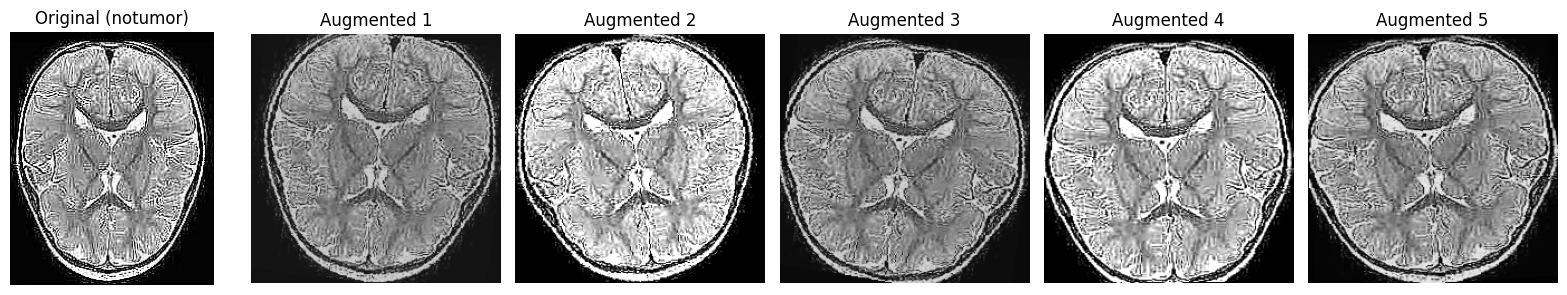

In [ ]:
import sys, json, torch, pandas as pd
sys.path.append(PROJECT)
import src.preprocessing as prep
import matplotlib.pyplot as plt
from PIL import Image

splits = pd.read_csv(f'{PROJECT}/data/splits.csv')
row = splits[splits.group == 'train'].iloc[0]
img = Image.open(row.path).convert('RGB')
aug = prep.get_transforms(train=True)

def show(t):
    mean = torch.tensor(prep.IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(prep.IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(img); axes[0].set_title(f'Original ({row.label})')
for k in range(1, 6):
    axes[k].imshow(show(aug(img))); axes[k].set_title(f'Augmented {k}')
for a in axes: a.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/augmentation_examples.png', dpi=200)
plt.show()

**Day 3: Step 1: Write the model builder**

In [ ]:
%%writefile {PROJECT}/src/train.py
import torch
import torch.nn as nn
from torchvision import models


def build_model(name: str, num_classes: int = 4):
    """Load a model pre-trained on ImageNet and replace its last layer."""
    if name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        head = model.fc
    elif name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        head = model.classifier
    else:
        raise ValueError(f'Unknown model: {name}')
    return model, head


def set_backbone_trainable(model, head, trainable: bool):
    """Stage 1: trainable=False (only the new last layer learns). Stage 2: True."""
    for p in model.parameters():
        p.requires_grad = trainable
    for p in head.parameters():          # the new last layer always learns
        p.requires_grad = True

Overwriting /content/drive/MyDrive/Medical-Vision-AI-XAI/src/train.py


**Step 2: Set up and test with one batch**

In [ ]:
# 1. Mount Drive and set the project path
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/Medical-Vision-AI-XAI'

# 2. Re-download the pictures if Colab was restarted
import os
from pathlib import Path
if not Path('/content/data/Training').exists():
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste Kaggle token: ')
    !pip install -q --upgrade kaggle
    !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/data --unzip
else:
    print('Pictures are already here.')

# 3. Imports
import sys, json, torch, pandas as pd, numpy as np
sys.path.append(PROJECT)
import importlib, src.preprocessing as prep, src.train as tr
importlib.reload(prep); importlib.reload(tr)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

# 4. Class order (fixed, never change it) and save it
class_to_idx = {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
json.dump(class_to_idx, open(f'{PROJECT}/data/class_to_idx.json', 'w'))
classes = sorted(class_to_idx, key=class_to_idx.get)
print('Classes:', class_to_idx)

# 5. Load the split and compute class weights
splits = pd.read_csv(f'{PROJECT}/data/splits.csv')
train_labels = splits[splits.group == 'train'].label
counts = train_labels.value_counts().reindex(classes).values
class_weights = torch.tensor(counts.sum() / (len(classes) * counts), dtype=torch.float32)
print('Weights:', class_weights.numpy().round(2))

# 6. Build the loaders
loaders = prep.make_loaders(splits, class_to_idx, batch_size=32)
print('Sizes:', {k: len(v.dataset) for k, v in loaders.items()})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pictures are already here.
Device: cuda
Classes: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Weights: [0.85 0.93 1.64 0.88]
Sizes: {'train': 3790, 'val': 948, 'test': 1600}


**Cell B: build ResNet-50 and test one batch**

In [ ]:
import torch.nn as nn

model, head = tr.build_model('resnet50')
model = model.to(device)
tr.set_backbone_trainable(model, head, False)       # Stage 1: only the new last layer learns

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f'Trainable parameters: {n_train:,} of {n_total:,}')

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=0.1)
images, labels = next(iter(loaders['train']))
images, labels = images.to(device), labels.to(device)

model.eval()
with torch.no_grad():
    out = model(images)
print('Output shape:', out.shape)
print('Loss before training:', round(criterion(out, labels).item(), 3))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 62.3MB/s]


Trainable parameters: 8,196 of 23,516,228
Output shape: torch.Size([32, 4])
Loss before training: 1.399


**Step 3a: Write the full src/train.py**

In [ ]:
%%writefile {PROJECT}/src/train.py
import time
import torch
import torch.nn as nn
import pandas as pd
from torchvision import models


def build_model(name: str, num_classes: int = 4):
    """Load a model pre-trained on ImageNet and replace its last layer."""
    if name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        head = model.fc
    elif name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        head = model.classifier
    else:
        raise ValueError(f'Unknown model: {name}')
    return model, head


def set_backbone_trainable(model, head, trainable: bool):
    """Stage 1: trainable=False (only the new last layer learns). Stage 2: True."""
    for p in model.parameters():
        p.requires_grad = trainable
    for p in head.parameters():
        p.requires_grad = True


def run_epoch(model, loader, criterion, device, optimizer=None, scaler=None):
    """One pass over a loader. Learns if an optimizer is given, otherwise only grades."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', enabled=(device == 'cuda')):
                outputs = model(images)
                loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            n += images.size(0)
    return total_loss / n, correct / n


def fit(model, head, loaders, class_weights, device, name, save_dir, results_dir,
        stage1_epochs=3, stage2_epochs=12, patience=4):
    """Two-stage training. Saves the best model (lowest validation loss) to Drive."""
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=0.1)
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    best_val, best_path = float('inf'), f'{save_dir}/{name}_best.pt'
    history = []

    stages = [(1, stage1_epochs, 1e-3, False),   # (stage, epochs, learning rate, unfreeze?)
              (2, stage2_epochs, 1e-4, True)]
    for stage, epochs, lr, unfreeze in stages:
        if epochs == 0:
            continue
        set_backbone_trainable(model, head, unfreeze)
        params = [p for p in model.parameters() if p.requires_grad]
        optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        bad_epochs = 0

        for ep in range(1, epochs + 1):
            t0 = time.time()
            tr_loss, tr_acc = run_epoch(model, loaders['train'], criterion, device, optimizer, scaler)
            va_loss, va_acc = run_epoch(model, loaders['val'], criterion, device)
            scheduler.step()
            secs = time.time() - t0

            saved = ''
            if va_loss < best_val:
                best_val, bad_epochs = va_loss, 0
                torch.save(model.state_dict(), best_path)
                saved = '  <- saved best'
            else:
                bad_epochs += 1

            history.append(dict(stage=stage, epoch=ep, train_loss=tr_loss, train_acc=tr_acc,
                                val_loss=va_loss, val_acc=va_acc, seconds=secs))
            print(f'Stage {stage} | epoch {ep:2d}/{epochs} | '
                  f'train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
                  f'val loss {va_loss:.3f} acc {va_acc:.3f} | {secs:.0f}s{saved}')

            if stage == 2 and bad_epochs >= patience:
                print(f'Early stopping: no improvement for {patience} epochs.')
                break

    model.load_state_dict(torch.load(best_path, map_location=device))   # go back to the best version
    hist = pd.DataFrame(history)
    hist.to_csv(f'{results_dir}/{name}_history.csv', index=False)
    return model, hist

Overwriting /content/drive/MyDrive/Medical-Vision-AI-XAI/src/train.py


In [ ]:
importlib.reload(tr)
model, head = tr.build_model('resnet50')
model = model.to(device)

model, hist = tr.fit(model, head, loaders, class_weights, device, 'smoke_test',
                     f'{PROJECT}/models', f'{PROJECT}/results',
                     stage1_epochs=1, stage2_epochs=0)

Stage 1 | epoch  1/1 | train loss 0.931 acc 0.745 | val loss 0.783 acc 0.791 | 34s  <- saved best


In [ ]:
importlib.reload(tr)
model, head = tr.build_model('resnet50')
model = model.to(device)

model, hist = tr.fit(model, head, loaders, class_weights, device, 'resnet50',
                     f'{PROJECT}/models', f'{PROJECT}/results',
                     stage1_epochs=3, stage2_epochs=12, patience=4)

Stage 1 | epoch  1/3 | train loss 0.937 acc 0.729 | val loss 0.770 acc 0.818 | 27s  <- saved best
Stage 1 | epoch  2/3 | train loss 0.729 acc 0.839 | val loss 0.702 acc 0.863 | 28s  <- saved best
Stage 1 | epoch  3/3 | train loss 0.690 acc 0.853 | val loss 0.687 acc 0.865 | 29s  <- saved best
Stage 2 | epoch  1/12 | train loss 0.577 acc 0.907 | val loss 0.490 acc 0.949 | 32s  <- saved best
Stage 2 | epoch  2/12 | train loss 0.468 acc 0.959 | val loss 0.448 acc 0.964 | 34s  <- saved best
Stage 2 | epoch  3/12 | train loss 0.431 acc 0.978 | val loss 0.429 acc 0.977 | 33s  <- saved best
Stage 2 | epoch  4/12 | train loss 0.412 acc 0.988 | val loss 0.430 acc 0.973 | 33s
Stage 2 | epoch  5/12 | train loss 0.404 acc 0.990 | val loss 0.428 acc 0.977 | 31s  <- saved best
Stage 2 | epoch  6/12 | train loss 0.392 acc 0.996 | val loss 0.412 acc 0.983 | 33s  <- saved best
Stage 2 | epoch  7/12 | train loss 0.390 acc 0.995 | val loss 0.412 acc 0.981 | 34s
Stage 2 | epoch  8/12 | train loss 0.384 ac

**Step 3c: Plot how it learned**

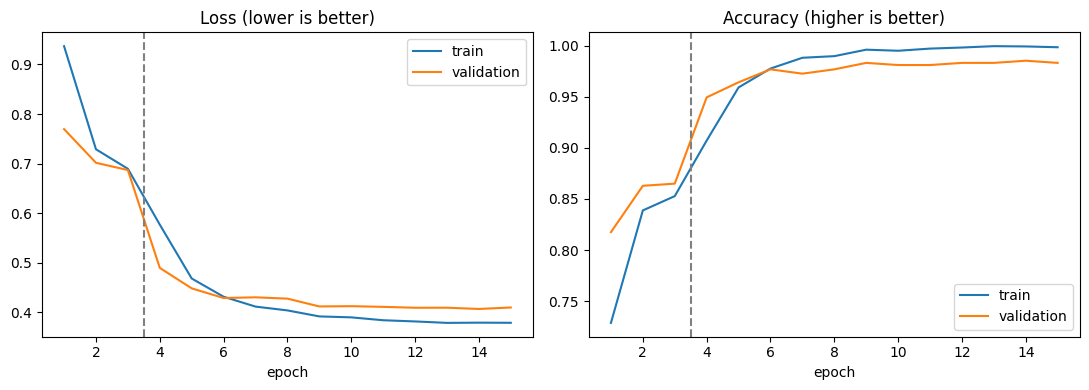

In [ ]:
import matplotlib.pyplot as plt
hist['step'] = range(1, len(hist) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.step, hist.train_loss, label='train'); ax[0].plot(hist.step, hist.val_loss, label='validation')
ax[0].set_title('Loss (lower is better)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(hist.step, hist.train_acc, label='train'); ax[1].plot(hist.step, hist.val_acc, label='validation')
ax[1].set_title('Accuracy (higher is better)'); ax[1].set_xlabel('epoch'); ax[1].legend()
for s in hist.index[hist.stage.diff() == 1]:
    for a in ax: a.axvline(hist.step[s] - 0.5, color='gray', ls='--')   # where Stage 2 begins
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/resnet50_training_curves.png', dpi=200)
plt.show()

**Step 3c: Plot how it learned**

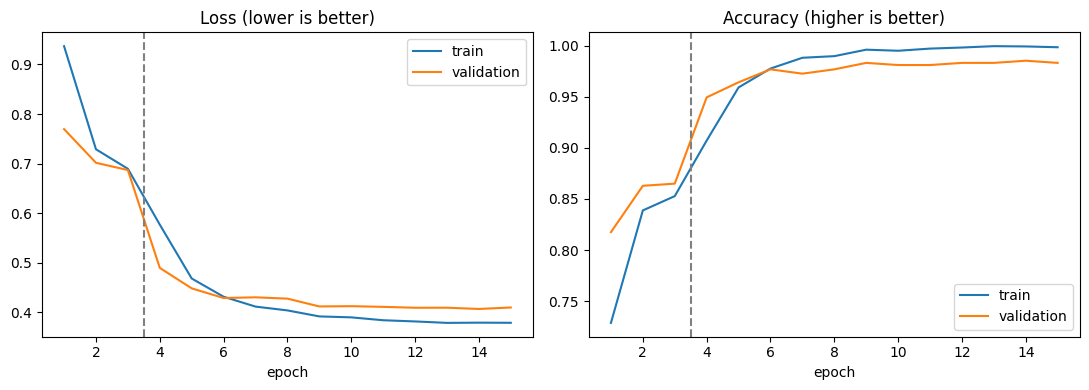

In [ ]:
import matplotlib.pyplot as plt
hist['step'] = range(1, len(hist) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.step, hist.train_loss, label='train'); ax[0].plot(hist.step, hist.val_loss, label='validation')
ax[0].set_title('Loss (lower is better)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(hist.step, hist.train_acc, label='train'); ax[1].plot(hist.step, hist.val_acc, label='validation')
ax[1].set_title('Accuracy (higher is better)'); ax[1].set_xlabel('epoch'); ax[1].legend()
for s in hist.index[hist.stage.diff() == 1]:
    for a in ax: a.axvline(hist.step[s] - 0.5, color='gray', ls='--')   # where Stage 2 begins
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/resnet50_training_curves.png', dpi=200)
plt.show()

In [ ]:
!ls -lh {PROJECT}/models {PROJECT}/results

/content/drive/MyDrive/Medical-Vision-AI-XAI/models:
total 181M
-rw------- 1 root root 91M Nov 13 17:25 resnet50_best.pt
-rw------- 1 root root 91M Nov 13 17:16 smoke_test_best.pt

/content/drive/MyDrive/Medical-Vision-AI-XAI/results:
total 3.9M
-rw------- 1 root root 1.6M Nov 13 16:58 augmentation_examples.png
-rw------- 1 root root  46K Nov 11 15:46 class_distribution.png
-rw------- 1 root root 1.6K Nov 13 17:25 resnet50_history.csv
-rw------- 1 root root 103K Nov 13 17:29 resnet50_training_curves.png
-rw------- 1 root root 2.3M Nov 11 15:46 sample_images.png
-rw------- 1 root root  156 Nov 13 17:16 smoke_test_history.csv


In [ ]:
importlib.reload(tr)
model_e, head_e = tr.build_model('efficientnet_b0')
model_e = model_e.to(device)

n_total = sum(p.numel() for p in model_e.parameters())
print(f'EfficientNet-B0 parameters: {n_total:,}')

model_e, hist_e = tr.fit(model_e, head_e, loaders, class_weights, device, 'efficientnet_b0',
                         f'{PROJECT}/models', f'{PROJECT}/results',
                         stage1_epochs=3, stage2_epochs=12, patience=4)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 110MB/s] 

EfficientNet-B0 parameters: 4,012,672


Stage 1 | epoch  1/3 | train loss 0.854 acc 0.767 | val loss 0.679 acc 0.866 | 35s  <- saved best
Stage 1 | epoch  2/3 | train loss 0.693 acc 0.837 | val loss 0.651 acc 0.890 | 31s  <- saved best
Stage 1 | epoch  3/3 | train loss 0.668 acc 0.858 | val loss 0.644 acc 0.889 | 31s  <- saved best
Stage 2 | epoch  1/12 | train loss 0.604 acc 0.889 | val loss 0.522 acc 0.938 | 37s  <- saved best
Stage 2 | epoch  2/12 | train loss 0.511 acc 0.939 | val loss 0.479 acc 0.954 | 34s  <- saved best
Stage 2 | epoch  3/12 | train loss 0.465 acc 0.963 | val loss 0.453 acc 0.963 | 36s  <- saved best
Stage 2 | epoch  4/12 | train loss 0.442 acc 0.975 | val loss 0.440 acc 0.978 | 35s  <- saved best
Stage 2 | epoch  5/12 | train loss 0.435 acc 0.980 | val loss 0.432 acc 0.976 | 35s  <- saved best
Stage 2 | epoch  6/12 | train loss 0.426 acc 0.984 | val loss 0.428 acc 0.981 | 37s  <- saved best
Stage 2 | epoch  7/12 | train loss 0.418 acc 0.987 | val loss 0.424 acc 0.980 | 35s  <- saved best
Stage 2 | epo

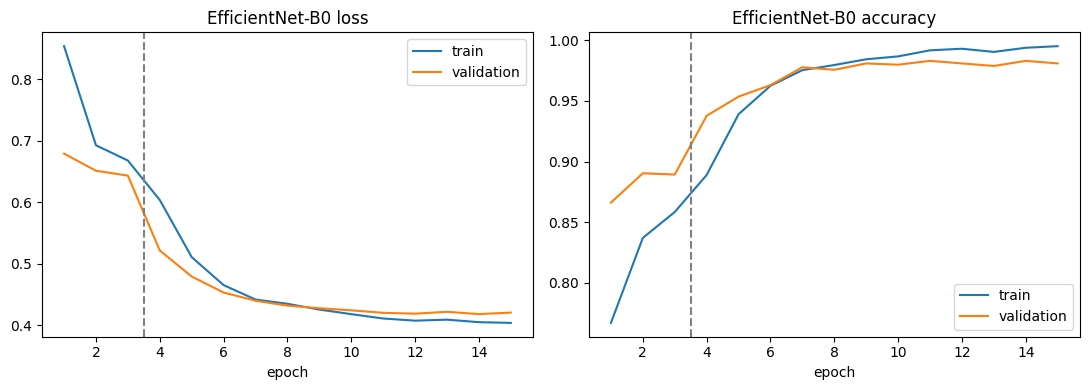

In [ ]:
hist_e['step'] = range(1, len(hist_e) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_e.step, hist_e.train_loss, label='train'); ax[0].plot(hist_e.step, hist_e.val_loss, label='validation')
ax[0].set_title('EfficientNet-B0 loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(hist_e.step, hist_e.train_acc, label='train'); ax[1].plot(hist_e.step, hist_e.val_acc, label='validation')
ax[1].set_title('EfficientNet-B0 accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
for s in hist_e.index[hist_e.stage.diff() == 1]:
    for a in ax: a.axvline(hist_e.step[s] - 0.5, color='gray', ls='--')
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/efficientnet_b0_training_curves.png', dpi=200)
plt.show()

**Task 1: Check that both saved models reload correctly**

In [ ]:
import torch.nn as nn
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=0.1)

for name in ['resnet50', 'efficientnet_b0']:
    m, _ = tr.build_model(name)
    m.load_state_dict(torch.load(f'{PROJECT}/models/{name}_best.pt', map_location=device))
    m = m.to(device)
    loss, acc = tr.run_epoch(m, loaders['val'], criterion, device)
    print(f'{name:16s} val loss {loss:.3f} | val acc {acc:.3f}')

NameError: name 'class_weights' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/Medical-Vision-AI-XAI'

import os
from pathlib import Path
if not Path('/content/data/Training').exists():
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste Kaggle token: ')
    !pip install -q --upgrade kaggle
    !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/data --unzip
else:
    print('Pictures are already here.')

import sys, json, torch, pandas as pd, numpy as np
sys.path.append(PROJECT)
import importlib, src.preprocessing as prep, src.train as tr, src.evaluate as ev
for mod in (prep, tr, ev):
    importlib.reload(mod)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

class_to_idx = {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
classes = sorted(class_to_idx, key=class_to_idx.get)
g, n = class_to_idx['glioma'], class_to_idx['notumor']

splits = pd.read_csv(f'{PROJECT}/data/splits.csv')
counts = splits[splits.group == 'train'].label.value_counts().reindex(classes).values
class_weights = torch.tensor(counts.sum() / (len(classes) * counts), dtype=torch.float32)
loaders = prep.make_loaders(splits, class_to_idx, batch_size=32)

test_df = splits[splits.group == 'test'].reset_index(drop=True)
if 'test_clean_unique' not in test_df.columns:
    manifest = pd.read_csv(f'{PROJECT}/data/manifest.csv')
    test_df = test_df.merge(manifest[['path', 'test_clean', 'test_clean_unique']], on='path', how='left')
true_idx = test_df.label.map(class_to_idx).values

subsets = {
    'Full':   np.ones(len(test_df), dtype=bool),
    'Clean':  test_df.test_clean.astype(bool).values,
    'Strict': test_df.test_clean_unique.astype(bool).values,
}
strict = subsets['Strict']

preds = {}
for name in ['resnet50', 'efficientnet_b0']:
    d = np.load(f'{PROJECT}/results/predictions_{name}.npz')
    assert (d['labels'] == true_idx).all(), 'Order mismatch!'
    preds[name] = d['probs']
r_pred = preds['resnet50'].argmax(1)

for name, p in preds.items():
    print(f'{name}: strict accuracy = {(p[strict].argmax(1) == true_idx[strict]).mean():.4f}  (expected 0.9508 / 0.9449)')

Mounted at /content/drive
Paste Kaggle token: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:08<00:00, 19.4MB/s]

Device: cuda
resnet50: strict accuracy = 0.9508  (expected 0.9508 / 0.9449)
efficientnet_b0: strict accuracy = 0.9449  (expected 0.9508 / 0.9449)


In [ ]:
code = r'''import torch
import torch.nn.functional as F


class GradCAM:
    """Grad-CAM written from scratch.

    1. Run the picture through the model, remembering the output of one layer (activations).
    2. Ask the model how the chosen class score depends on that layer (gradients).
    3. Average the gradients per channel -> one importance weight per channel.
    4. Weighted sum of the channels, keep only positive evidence (ReLU), stretch to 224x224.
    """

    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.acts, self.grads = None, None
        self.handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        self.acts = output.detach()
        output.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x, class_idx=None):
        """x: one picture, shape [1, 3, 224, 224]. Returns heatmap, class used, probabilities."""
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(1))
        logits[0, class_idx].backward()

        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        probs = torch.softmax(logits.detach(), dim=1)[0]
        return cam.cpu().numpy(), class_idx, probs.cpu().numpy()

    def close(self):
        self.handle.remove()


def target_layer_for(model, name):
    """The last convolutional block of each model."""
    if name == "resnet50":
        return model.layer4[-1]
    if name == "efficientnet_b0":
        return model.features[-1]
    raise ValueError(name)
'''
with open(f'{PROJECT}/src/gradcam.py', 'w') as f:
    f.write(code)
print('Saved gradcam.py,', len(code.splitlines()), 'lines')

import src.gradcam as gc
importlib.reload(gc)
print([x for x in dir(gc) if x in ('GradCAM', 'target_layer_for')])

Saved gradcam.py, 49 lines
['GradCAM', 'target_layer_for']


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 69.7MB/s]


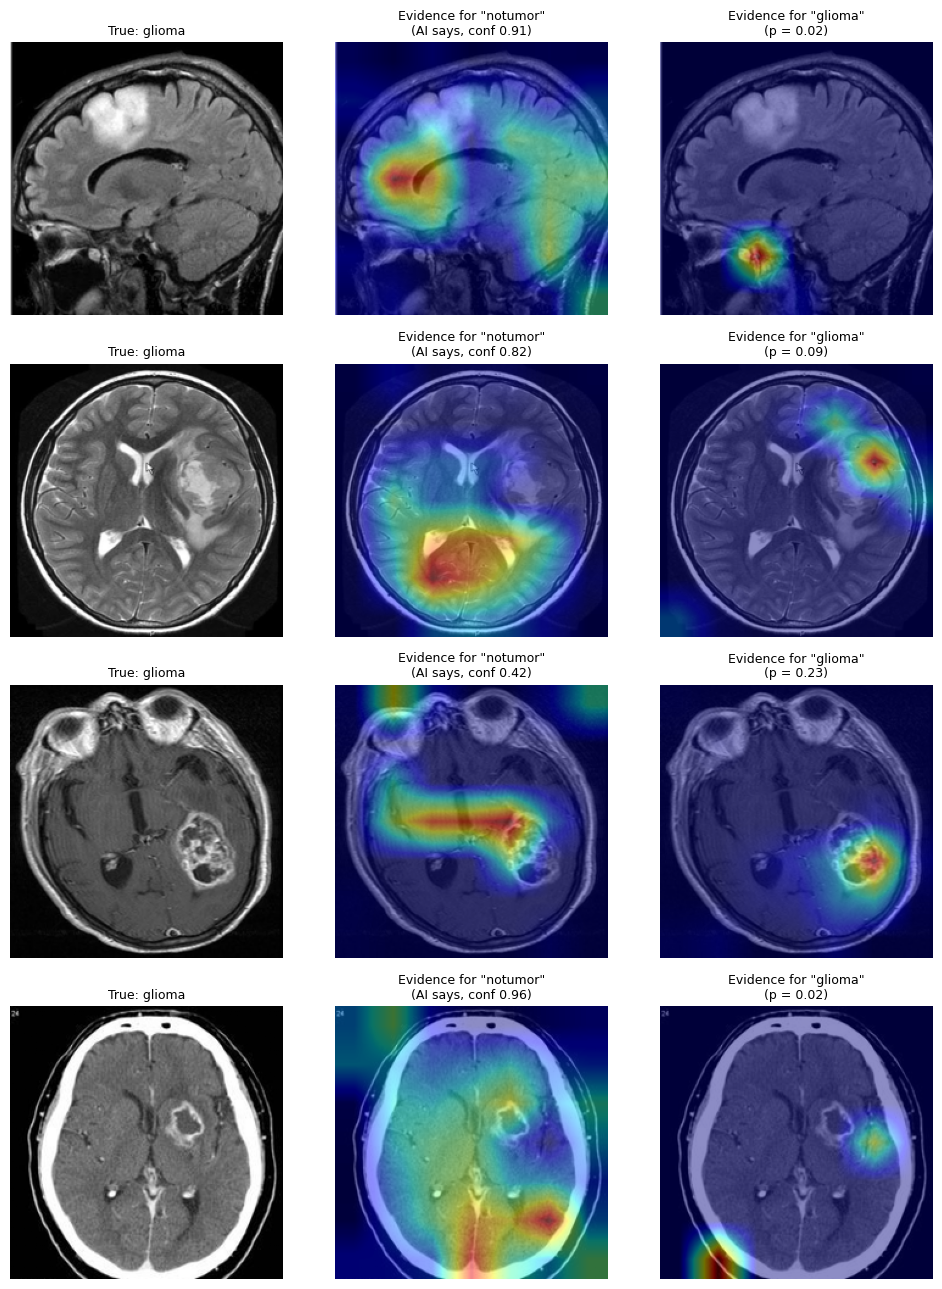

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def explain(model, cam_tool, path, true_label, device):
    img = Image.open(path).convert('RGB')
    x = prep.get_transforms(train=False)(img).unsqueeze(0).to(device)
    cam_pred, k_pred, probs = cam_tool(x)
    cam_true, _, _ = cam_tool(x, class_idx=class_to_idx[true_label])
    show = np.asarray(img.resize((224, 224)).convert('L'))
    return show, cam_pred, cam_true, k_pred, probs

def draw(axes, show, cam_pred, cam_true, k_pred, probs, true_label):
    axes[0].imshow(show, cmap='gray'); axes[0].set_title(f'True: {true_label}', fontsize=9)
    for a, cam, title in [
        (axes[1], cam_pred, f'Evidence for "{classes[k_pred]}"\n(AI says, conf {probs[k_pred]:.2f})'),
        (axes[2], cam_true, f'Evidence for "{true_label}"\n(p = {probs[class_to_idx[true_label]]:.2f})')]:
        a.imshow(show, cmap='gray'); a.imshow(cam, cmap='jet', alpha=0.45); a.set_title(title, fontsize=9)
    for a in axes: a.axis('off')

name = 'resnet50'
model, _ = tr.build_model(name)
model.load_state_dict(torch.load(f'{PROJECT}/models/{name}_best.pt', map_location=device))
model = model.to(device)
cam_tool = gc.GradCAM(model, gc.target_layer_for(model, name))

missed = np.where(strict & (true_idx == g) & (r_pred == n))[0]
fig, axes = plt.subplots(4, 3, figsize=(10, 13))
for row, i in zip(axes, missed[:4]):
    draw(row, *explain(model, cam_tool, test_df.path[i], 'glioma', device), 'glioma')
plt.tight_layout()
plt.savefig(f'{PROJECT}/results/gradcam_missed_gliomas_resnet50.png', dpi=200)
plt.show()

In [ ]:
KGAT_3212c286107f1f7f760fe067a31ef787

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/Medical-Vision-AI-XAI'

import os
from pathlib import Path
if not Path('/content/data/Training').exists():
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste Kaggle token: ')
    !pip install -q --upgrade kaggle
    !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/data --unzip
else:
    print('Pictures are already here.')

import sys, json, torch, pandas as pd, numpy as np
sys.path.append(PROJECT)
import importlib, src.preprocessing as prep, src.train as tr, src.evaluate as ev
for mod in (prep, tr, ev):
    importlib.reload(mod)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

class_to_idx = {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
classes = sorted(class_to_idx, key=class_to_idx.get)
g, n = class_to_idx['glioma'], class_to_idx['notumor']

splits = pd.read_csv(f'{PROJECT}/data/splits.csv')
test_df = splits[splits.group == 'test'].reset_index(drop=True)
if 'test_clean_unique' not in test_df.columns:
    manifest = pd.read_csv(f'{PROJECT}/data/manifest.csv')
    test_df = test_df.merge(manifest[['path', 'test_clean', 'test_clean_unique']], on='path', how='left')
true_idx = test_df.label.map(class_to_idx).values

strict = test_df.test_clean_unique.astype(bool).values

preds = {}
for name in ['resnet50', 'efficientnet_b0']:
    d = np.load(f'{PROJECT}/results/predictions_{name}.npz')
    assert (d['labels'] == true_idx).all(), 'Order mismatch!'
    preds[name] = d['probs']
r_pred = preds['resnet50'].argmax(1)

for name, p in preds.items():
    print(f'{name}: strict accuracy = {(p[strict].argmax(1) == true_idx[strict]).mean():.4f}  (expected 0.9508 / 0.9449)')

Mounted at /content/drive
Paste Kaggle token: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 156MB/s]

Device: cpu
resnet50: strict accuracy = 0.9508  (expected 0.9508 / 0.9449)
efficientnet_b0: strict accuracy = 0.9449  (expected 0.9508 / 0.9449)


In [ ]:
import shutil
out = f'{PROJECT}/app/samples'
os.makedirs(out, exist_ok=True)
rng = np.random.default_rng(7)
ok = (r_pred == true_idx)

for c in classes:
    idx = np.where(strict & ok & (true_idx == class_to_idx[c]))[0]
    for j, i in enumerate(rng.choice(idx, 2, replace=False), 1):
        shutil.copy(test_df.path[i], f'{out}/{c}_{j}.jpg')

missed = np.where(strict & (true_idx == g) & (r_pred == n))[0]
for j, i in enumerate(rng.choice(missed, 2, replace=False), 1):
    shutil.copy(test_df.path[i], f'{out}/glioma_MISSED_{j}.jpg')

print(sorted(os.listdir(out)))

['glioma_1.jpg', 'glioma_2.jpg', 'glioma_MISSED_1.jpg', 'glioma_MISSED_2.jpg', 'meningioma_1.jpg', 'meningioma_2.jpg', 'notumor_1.jpg', 'notumor_2.jpg', 'pituitary_1.jpg', 'pituitary_2.jpg']


In [1]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/Medical-Vision-AI-XAI'

import os
from pathlib import Path
if not Path('/content/data/Training').exists():
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste Kaggle token: ')
    !pip install -q --upgrade kaggle
    !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/data --unzip
else:
    print('Pictures are already here.')

import sys, json, torch, pandas as pd, numpy as np
sys.path.append(PROJECT)
import importlib, src.preprocessing as prep, src.train as tr, src.evaluate as ev
for mod in (prep, tr, ev):
    importlib.reload(mod)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

class_to_idx = {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
classes = sorted(class_to_idx, key=class_to_idx.get)
g, n = class_to_idx['glioma'], class_to_idx['notumor']

splits = pd.read_csv(f'{PROJECT}/data/splits.csv')
test_df = splits[splits.group == 'test'].reset_index(drop=True)
if 'test_clean_unique' not in test_df.columns:
    manifest = pd.read_csv(f'{PROJECT}/data/manifest.csv')
    test_df = test_df.merge(manifest[['path', 'test_clean', 'test_clean_unique']], on='path', how='left')
true_idx = test_df.label.map(class_to_idx).values

strict = test_df.test_clean_unique.astype(bool).values

preds = {}
for name in ['resnet50', 'efficientnet_b0']:
    d = np.load(f'{PROJECT}/results/predictions_{name}.npz')
    assert (d['labels'] == true_idx).all(), 'Order mismatch!'
    preds[name] = d['probs']
r_pred = preds['resnet50'].argmax(1)

for name, p in preds.items():
    print(f'{name}: strict accuracy = {(p[strict].argmax(1) == true_idx[strict]).mean():.4f}  (expected 0.9508 / 0.9449)')

Mounted at /content/drive
Paste Kaggle token: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 85.5MB/s]

Device: cuda
resnet50: strict accuracy = 0.9508  (expected 0.9508 / 0.9449)
efficientnet_b0: strict accuracy = 0.9449  (expected 0.9508 / 0.9449)


In [2]:
from PIL import Image
def stats(p):
    rgb = np.asarray(Image.open(p).convert('RGB').resize((224, 224))).astype(np.float32)
    return (rgb.max(2) - rgb.min(2)).mean(), (rgb.mean(2) < 25).mean()

S = np.array([stats(p) for p in test_df.path[strict]])
print('Share of real test MRIs that would trigger the warning:')
print('  colorfulness > 20 :', (S[:, 0] > 20).mean().round(3))
print('  dark share < 0.08 :', (S[:, 1] < 0.08).mean().round(3))
print('  either            :', ((S[:, 0] > 20) | (S[:, 1] < 0.08)).mean().round(3))

Share of real test MRIs that would trigger the warning:
  colorfulness > 20 : 0.0
  dark share < 0.08 : 0.009
  either            : 0.009
